# What have we funded on batteries? A first look at the CORDIS data

**The request.** A policy unit asks, through its Feedback to Policy (F2P) Correspondent: *"We need to know what we've funded on batteries and whether it's working — can you build us something with AI?"*

One sentence, three different needs, and a solution asked for before the need is clear:

1. **What have we funded?** An inventory of the portfolio: which projects, how much, when, under which topics.
2. **Is it working?** Results and impact: what came out of those projects, which is a much harder question than the first.
3. **Where are the gaps?** A comparison between what was funded and what the policy wants, which needs a target the request does not name.

"Build us something with AI" is a means, not a need. Before choosing any tool, the first step is to check whether the data we already have can answer question 1, and how far. This notebook does that check on public CORDIS data: where the data comes from, on what terms it can be reused, and what it is worth.

## 1. Data source and reuse terms

**Source.** CORDIS, the Commission's public repository of EU-funded research projects. The Horizon Europe dataset is published on [data.europa.eu](https://data.europa.eu/data/datasets/cordis-eu-research-projects-under-horizon-europe-2021-2027) and exported as CSV archives from `cordis.europa.eu/data/`. Six files are used here, three of them from the first archive:

| File | Archive | What it holds |
|---|---|---|
| `project.csv` | `cordis-HORIZONprojects-csv.zip` | one row per project: title, objective (the abstract), dates, EU contribution, topic, funding scheme |
| `euroSciVoc.csv` | `cordis-HORIZONprojects-csv.zip` | the European Science Vocabulary labels attached to each project |
| `organization.csv` | `cordis-HORIZONprojects-csv.zip` | one row per participation: organisation, country, type, role, EU contribution |
| `projectPublications.csv` | `cordis-HORIZONprojectPublications-csv.zip` | publications reported by projects |
| `projectDeliverables.csv` | `cordis-HORIZONprojectDeliverables-csv.zip` | one row per deliverable: type, short description, link to the document |
| `reportSummaries.csv` | `cordis-HORIZONreports-csv.zip` | one row per periodic report: title and attachment reference |

The deliverable and report files are read in section 6 for what they can say about "is it working?": in these CSV files, titles and short descriptions, not the documents themselves.

**Reuse terms.** CORDIS content is covered by the Commission's reuse policy, implemented by [Decision 2011/833/EU](https://eur-lex.europa.eu/eli/dec/2011/833/oj) of 12 December 2011 on the reuse of Commission documents. CORDIS releases its datasets under the Creative Commons Attribution 4.0 (CC BY 4.0) licence: reuse is allowed, including commercially, provided the source is credited and any changes are indicated. This notebook credits CORDIS, reads the files as published, and states below how many rows it excludes because they cannot be parsed.

**Snapshot.** The files are not committed to this repository (about 60 MB). The cell below downloads them if they are missing and compares their SHA-256 fingerprint with `data/SHA256SUMS`, recorded from the archives downloaded from CORDIS on 8 October 2026. CORDIS republishes the dataset regularly, so a later download may differ: the notebook then warns and continues, and the figures below may move.

In [1]:
import sys

sys.path.insert(0, "src")

import cordis

LABELS = {"eu_contribution_meur": "EU contribution, EUR million", "start_year": "start year", "part": "programme part", "activityType": "type of organisation", "share_published": "share with a publication"}

def show(table):
    """Print a table with plain column and index names."""
    if hasattr(table, "columns"):
        table = table.rename(columns=LABELS)
    print(table.rename_axis(LABELS.get(table.index.name, table.index.name)).to_string())

projects_zip = cordis.fetch_zip("cordis-HORIZONprojects-csv.zip")
publications_zip = cordis.fetch_zip("cordis-HORIZONprojectPublications-csv.zip")

projects, projects_excluded = cordis.read_from_zip(projects_zip, "project.csv")
eurosci, eurosci_excluded = cordis.read_from_zip(projects_zip, "euroSciVoc.csv")
publications, publications_excluded = cordis.read_from_zip(publications_zip, "projectPublications.csv")

for name, df, excluded in [
    ("project.csv", projects, projects_excluded),
    ("euroSciVoc.csv", eurosci, eurosci_excluded),
    ("projectPublications.csv", publications, publications_excluded),
]:
    print(f"{name:28} {len(df):>8,} rows read   {excluded:>5,} rows excluded ({excluded / (len(df) + excluded):.2%})")

project.csv                    23,756 rows read     198 rows excluded (0.83%)
euroSciVoc.csv                 53,196 rows read       0 rows excluded (0.00%)
projectPublications.csv        95,383 rows read      22 rows excluded (0.02%)


## 2. Quality check

Three things a reader should know before trusting any figure computed from these files.

**Rows that cannot be parsed.** The CSV files quote every field, but a few free-text fields (project objectives, publication titles) contain an unescaped quote that breaks the row. Those rows are counted above for each file, excluded, and not repaired: under one percent of projects and a handful of publications, which is acceptable for a portfolio overview, but it means the totals below are slightly below the true totals and any project-level lookup may miss a project for that reason alone.

**Money read as numbers.** CORDIS writes amounts with a decimal comma (`2073781,25`). The loader converts them to numbers, so sums are sums and not string concatenations. The check below prints the column type and the total EU contribution of the whole Horizon Europe portfolio in the file.

In [2]:
print("Amounts read as numbers:", "yes" if projects["ecMaxContribution"].dtype.kind == "f" else projects["ecMaxContribution"].dtype)
print(f"Total EU contribution, all projects in file: EUR {projects['ecMaxContribution'].sum() / 1e9:,.1f} billion")
print(f"Projects with no EU contribution recorded: {projects['ecMaxContribution'].isna().sum():,}")

Amounts read as numbers: yes
Total EU contribution, all projects in file: EUR 63.5 billion
Projects with no EU contribution recorded: 0


**Coverage of the ready-made taxonomy.** CORDIS attaches European Science Vocabulary (euroSciVoc) labels to projects. If every project carried them, "battery projects" could be read straight off the taxonomy. The cell below measures how many projects carry at least one label.

In [3]:
labelled = projects["id"].isin(eurosci["projectID"])
print(f"Projects with at least one euroSciVoc label: {labelled.sum():,} of {len(projects):,} ({labelled.mean():.1%})")
print(f"Projects without any euroSciVoc label:       {(~labelled).sum():,} ({(~labelled).mean():.1%})")

Projects with at least one euroSciVoc label: 19,793 of 23,756 (83.3%)
Projects without any euroSciVoc label:       3,963 (16.7%)


## 3. FAIR check

A short check against the FAIR principles (findable, accessible, interoperable, reusable), which is the reflex expected before building anything on a dataset.

| Principle | What holds | What does not |
|---|---|---|
| **Findable** | Dataset catalogued on data.europa.eu with a stable identifier; each project has a persistent id and almost every project a grant DOI. | No version identifier on the CSV archives: the only way to know which snapshot was used is the fingerprint kept in this repository. |
| **Accessible** | Open download, no account, no API key; standard CSV. | Archives are republished in place, so a given snapshot is not retrievable afterwards. |
| **Interoperable** | Shared project ids across the three files make joins straightforward; euroSciVoc is a controlled vocabulary. | Decimal commas and unescaped quotes need a tolerant loader; a fraction of projects carries no euroSciVoc label. |
| **Reusable** | Clear licence (CC BY 4.0 under Decision 2011/833/EU); documentation shipped inside each archive. | No change log between snapshots, so figures can move without notice. |

**What this means for the request.** The data is good enough to start answering "what have we funded?" with a documented, reproducible method, as long as the snapshot is pinned and the excluded rows are reported. It is not, on its own, enough to answer "is it working?", and the taxonomy coverage means "battery projects" will need a definition agreed with the unit rather than a label read off the shelf.

## 4. Scope: what counts as a "battery" project?

No field in CORDIS says "this is a battery project". Two ways to find them:

- **The ready-made taxonomy.** euroSciVoc has a label *natural sciences / chemical sciences / electrochemistry / electric batteries*. It is precise, but section 2 showed that not every project carries labels, and a label at that depth is rarer still.
- **A keyword rule.** A plain list of terms, searched in the project text. It is readable by anyone, which is the point: the unit can challenge the list, line by line, before any count is produced.

The rule is applied twice: to the **title only** (narrow: batteries are what the project is about) and to **title + objective + keywords** (broad: batteries are mentioned somewhere). The gap between the two is the first thing to show the F2P Correspondent, because it is the size of the definition problem.

In [4]:
TERMS = ["battery", "batteries", "lithium-ion", "li-ion", "sodium-ion", "solid-state cell"]

in_title = cordis.matches_terms(projects, TERMS, ["title"])
in_text = cordis.matches_terms(projects, TERMS, ["title", "objective", "keywords"])

print(f"Narrow definition, term in the title:                    {in_title.sum():>5,} projects")
print(f"Broad definition, term in title, objective or keywords:  {in_text.sum():>5,} projects  (x{in_text.sum() / in_title.sum():.1f})")
print(f"In the broad set but not the narrow one:                 {(in_text & ~in_title).sum():>5,} projects")

Narrow definition, term in the title:                      278 projects
Broad definition, term in title, objective or keywords:    662 projects  (x2.4)
In the broad set but not the narrow one:                   384 projects


**For the F2P Correspondent.** The broad definition returns more than twice as many projects as the narrow one, and neither is right by itself. The narrow set misses projects where batteries are one work package among others. The broad set catches projects that only mention batteries once, battery-free devices and a few that use the word in another sense ("a battery of tests"). The cell below sizes this grey zone: projects where the term is not in the title and appears fewer than three times. Any model would only be useful on these. The cut at three mentions is mine; the distribution of mentions is printed so that the unit can move it. The unit decides first whether a passing mention is in scope at all.

In [5]:
import re

text = projects[["title", "objective", "keywords"]].fillna("").astype(str).agg(" ".join, axis=1).str.lower()
mentions = text.str.count("|".join(re.escape(t) for t in TERMS))
other_sense = text.str.contains(r"\bbattery of\b")
battery_free = text.str.contains(r"battery-free|batteryless|battery-less|battery free")
once_outside_title = in_text & ~in_title & (mentions == 1)
grey = in_text & ~in_title & (mentions < 3)

print(f"Broad set:                                              {in_text.sum():>5,}")
print(f"  term used in another sense ('a battery of ...'):        {(in_text & other_sense).sum():>5,}")
print(f"  battery-free or batteryless devices:                   {(in_text & battery_free).sum():>5,}")
print(f"  term mentioned once, outside the title:                {once_outside_title.sum():>5,}")
print(f"Grey zone (not in title, fewer than three mentions):    {grey.sum():>5,}  ({grey.mean() / in_text.mean():.0%} of the broad set)")
print(f"  of which fellowships: {(grey & projects['fundingScheme'].str.contains('MSCA', na=False)).sum()}, ERC grants: {(grey & projects['fundingScheme'].str.startswith('HORIZON-ERC', na=False)).sum()}")
print("Mentions per project in the broad set, outside the title: " + ", ".join(f"{k}: {v}" for k, v in mentions[in_text & ~in_title].clip(upper=4).value_counts().sort_index().rename({4: "4 or more"}).items()))

print(f"Battery-free devices with the term in the title (in the narrow set): {(in_title & battery_free).sum()}")

examples = projects[in_text & other_sense].copy()
examples["snippet"] = examples["objective"].fillna("").apply(
    lambda s: next((m.group(0) for m in re.finditer(r".{0,50}battery of.{0,50}", s, flags=re.I)), "")
)
examples[["acronym", "snippet"]].head(4).style.hide(axis="index")

Broad set:                                                662
  term used in another sense ('a battery of ...'):           14
  battery-free or batteryless devices:                      23
  term mentioned once, outside the title:                  237
Grey zone (not in title, fewer than three mentions):      292  (44% of the broad set)
  of which fellowships: 83, ERC grants: 59
Mentions per project in the broad set, outside the title: 1: 237, 2: 55, 3: 30, 4 or more: 62
Battery-free devices with the term in the title (in the narrow set): 5


acronym,snippet
ConnectomesToANNs,n of how these principles impact performance on a battery of deep learning tasks. This unique methodology will
LgDel-mPFC,"t of OXT and dopamine real-time dynamics during a battery of non-social and social cognitive tests, I aim to d"
SENSE,"ng their predictability of human performance in a battery of semantic tasks. Overall, SENSE will make a soli"
CHROMSEG,questions and will exploit our recently generated battery of molecular reagents. Outcome of our work will prov


**What the taxonomy says about the same projects.** The cell below counts, in the broad set, the projects that carry the euroSciVoc label *electric batteries*. Every labelled project that could be read from the file is caught by the keyword rule (the two missing ones are among the unreadable rows of section 2), so the rule does not miss what the taxonomy knows. The reverse is the problem: the label covers under a tenth of the broad set. euroSciVoc describes scientific fields, not policy themes, and a battery recycling or grid-storage project legitimately sits elsewhere in it. For the unit, it means "battery projects" cannot be read off the corporate taxonomy at the grain the question needs. Agreeing a definition, and curating the metadata that records it, is part of the work.

In [6]:
battery_label = eurosci[eurosci["euroSciVocPath"].str.contains("electric batteries", case=False, na=False)]["projectID"].unique()
readable = projects["id"].isin(battery_label)

print(f"Projects labelled 'electric batteries' in euroSciVoc:            {len(battery_label):>4,}")
print(f"  of which readable in project.csv (the rest are unparseable rows): {readable.sum():>4,}")
print(f"  of which caught by the broad keyword rule:                        {(readable & in_text).sum():>4,}")
print(f"Share of the broad set that carries the label:                     {readable[in_text].mean():>5.1%}")

Projects labelled 'electric batteries' in euroSciVoc:              59
  of which readable in project.csv (the rest are unparseable rows):   57
  of which caught by the broad keyword rule:                          57
Share of the broad set that carries the label:                      8.6%


**Does "what we funded" include the partnership?** The BATT4EU partnership (Cluster 5, Destination 2 of the work programme) is where most of the programmatic battery research sits. The partnership is not a field in CORDIS, but its calls are: the topic identifiers of Destination 2 can be counted. Whether those projects, the Marie Skłodowska-Curie fellowships and the ERC grants count as "what we funded on batteries" is not a data question. It is the first question to put back to the unit.

In [7]:
import pandas as pd

scope = projects[in_text].copy()
scope["start_year"] = pd.to_datetime(scope["startDate"], errors="coerce").dt.year
scope["is_msca"] = scope["fundingScheme"].str.contains("MSCA", na=False)
scope["is_d2"] = scope["topics"].str.contains(r"CL5-20\d\d-D2", na=False)

print(f"Broad set: {len(scope):,} projects")
print(f"  under a Cluster 5 / Destination 2 topic (where the BATT4EU calls sit): {scope['is_d2'].sum():>4,}")
print(f"  Marie Skłodowska-Curie fellowships and networks:                        {scope['is_msca'].sum():>4,}  ({scope['is_msca'].mean():.0%})")
print(f"  ERC grants:                                                             {scope['fundingScheme'].str.startswith('HORIZON-ERC').sum():>4,}")

Broad set: 662 projects
  under a Cluster 5 / Destination 2 topic (where the BATT4EU calls sit):   88
  Marie Skłodowska-Curie fellowships and networks:                         221  (33%)
  ERC grants:                                                              103


## 5. What was funded, for the broad definition

With the broad definition as a working scope, the first need can be answered in counts: projects and EU contribution by start year, and by part of the programme (the `legalBasis` field, which names the pillar and cluster). Fellowships are shown apart: they are a third of the set and they fund a researcher's training, not a research agenda. Whether they belong in the answer is the unit's call. Figures are as of the snapshot of 8 October 2026 and exclude the unreadable rows counted in section 2.

In [8]:
by_year = (
    scope.groupby("start_year")
    .agg(projects=("id", "size"), eu_contribution_meur=("ecMaxContribution", lambda s: s.sum() / 1e6), fellowships=("is_msca", "sum"))
    .round(1)
)
by_year.index = by_year.index.astype(int)
show(by_year)
print(f"\nTotal: {len(scope):,} projects, EUR {scope['ecMaxContribution'].sum() / 1e9:.2f} billion of EU contribution")

            projects  EU contribution, EUR million  fellowships
start year                                                     
2022              94                         337.7           14
2023             156                         654.9           38
2024             137                         502.9           42
2025             109                         316.4           47
2026             135                         412.2           53
2027              31                          29.7           27

Total: 662 projects, EUR 2.25 billion of EU contribution


In [9]:
PROGRAMME_PART = {
    "HORIZON.1.1": "Pillar I - ERC",
    "HORIZON.1.2": "Pillar I - Marie Sklodowska-Curie",
    "HORIZON.1.3": "Pillar I - Research infrastructures",
    "HORIZON.2.1": "Pillar II - Cluster 1 Health",
    "HORIZON.2.4": "Pillar II - Cluster 4 Digital, industry, space",
    "HORIZON.2.5": "Pillar II - Cluster 5 Climate, energy, mobility",
    "HORIZON.2.6": "Pillar II - Cluster 6 Food, bioeconomy, environment",
    "HORIZON.3.1": "Pillar III - European Innovation Council",
    "HORIZON.3.2": "Pillar III - European Institute of Innovation and Technology",
    "HORIZON.3.3": "Pillar III - European innovation ecosystems",
    "HORIZON.4.1": "Widening participation",
}
by_part = (
    scope.assign(part=scope["legalBasis"].map(PROGRAMME_PART).fillna(scope["legalBasis"]))
    .groupby("part")
    .agg(projects=("id", "size"), eu_contribution_meur=("ecMaxContribution", lambda s: s.sum() / 1e6))
    .sort_values("eu_contribution_meur", ascending=False)
    .round(1)
)
show(by_part)

                                                              projects  EU contribution, EUR million
programme part                                                                                      
Pillar II - Cluster 5 Climate, energy, mobility                    178                        1266.1
Pillar II - Cluster 4 Digital, industry, space                      56                         370.3
Pillar III - European Innovation Council                            87                         215.3
Pillar I - ERC                                                     103                         131.0
Pillar I - Marie Sklodowska-Curie                                  214                         125.7
Pillar II - Cluster 6 Food, bioeconomy, environment                  6                          59.2
Pillar III - European innovation ecosystems                          1                          48.0
Widening participation                                              15                     

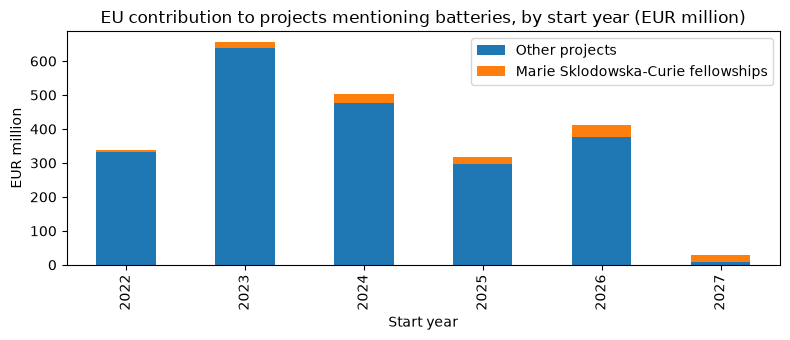

In [10]:
import matplotlib.pyplot as plt

split = scope.groupby(["start_year", "is_msca"])["ecMaxContribution"].sum().unstack(fill_value=0) / 1e6
split.index = split.index.astype(int)
split.columns = ["Other projects", "Marie Sklodowska-Curie fellowships"]
ax = split.plot.bar(stacked=True, figsize=(8, 3.5))
ax.set_title("EU contribution to projects mentioning batteries, by start year (EUR million)")
ax.set_xlabel("Start year")
ax.set_ylabel("EUR million")
plt.tight_layout()
plt.show()

**Research or demonstration?** The funding instrument says what kind of work was bought: research and innovation actions (RIA) explore, innovation actions (IA) demonstrate at scale, the European Innovation Council (EIC) backs start-ups, the European Research Council (ERC) funds frontier science, coordination and support actions (CSA) fund networks, and fellowships train researchers. The instrument is read from the funding scheme, so a few fellowships sit under other programme parts in the table above (214 against 221). The chart below is the single view I would show the unit first.

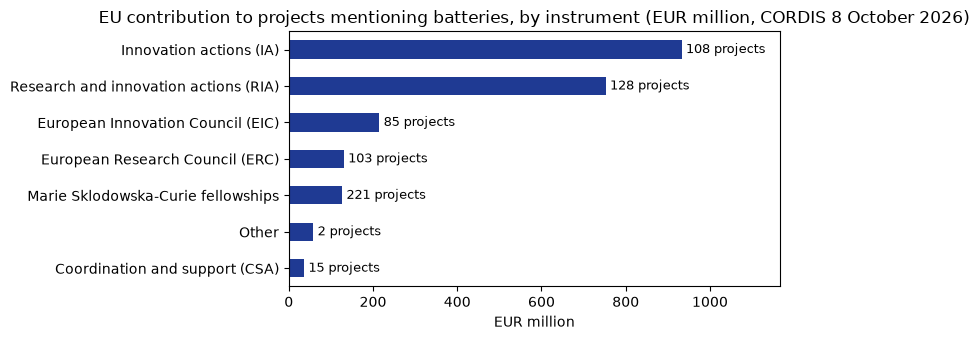

                                       projects  EU contribution, EUR million
instrument                                                                   
Innovation actions (IA)                     108                         933.0
Research and innovation actions (RIA)       128                         752.7
European Innovation Council (EIC)            85                         215.2
European Research Council (ERC)             103                         131.0
Marie Sklodowska-Curie fellowships          221                         126.8
Other                                         2                          58.4
Coordination and support (CSA)               15                          36.6


In [11]:
import matplotlib.pyplot as plt

INSTRUMENT = {
    "HORIZON-IA": "Innovation actions (IA)",
    "HORIZON-RIA": "Research and innovation actions (RIA)",
    "HORIZON-JU-IA": "Innovation actions (IA)",
    "HORIZON-JU-RIA": "Research and innovation actions (RIA)",
    "HORIZON-CSA": "Coordination and support (CSA)",
    "HORIZON-JU-CSA": "Coordination and support (CSA)",
}
def instrument(scheme):
    if "MSCA" in scheme:
        return "Marie Sklodowska-Curie fellowships"
    if scheme.startswith("HORIZON-ERC"):
        return "European Research Council (ERC)"
    if scheme.startswith("HORIZON-EIC"):
        return "European Innovation Council (EIC)"
    return INSTRUMENT.get(scheme, "Other")

scope["instrument"] = scope["fundingScheme"].fillna("").map(instrument)
by_instrument = (
    scope.groupby("instrument")
    .agg(projects=("id", "size"), eu_contribution_meur=("ecMaxContribution", lambda s: s.sum() / 1e6))
    .sort_values("eu_contribution_meur")
)
ax = by_instrument["eu_contribution_meur"].plot.barh(figsize=(8, 3.5), color="#1F3A93")
for y, (n, m) in enumerate(zip(by_instrument["projects"], by_instrument["eu_contribution_meur"])):
    ax.text(m + 10, y, f"{n} projects", va="center", fontsize=9)
ax.set_title("EU contribution to projects mentioning batteries, by instrument (EUR million, CORDIS 8 October 2026)")
ax.set_xlabel("EUR million")
ax.set_ylabel("")
ax.set_xlim(0, by_instrument["eu_contribution_meur"].max() * 1.25)
plt.tight_layout()
plt.show()
show(by_instrument.round(1).sort_values("eu_contribution_meur", ascending=False))

**Who takes part?** The organisation file lists every participation with its country, type and role. For the projects that are neither fellowships nor ERC grants (the collaborative core of the set), one line is enough for the request: how many partners, and what kind. These are participations, not organisations: a university that takes part in ten projects counts ten times, and organisation names are not harmonised across projects.

In [12]:
organisations, organisations_excluded = cordis.read_from_zip(projects_zip, "organization.csv")
print(f"organization.csv {len(organisations):,} rows read, {organisations_excluded} rows excluded")

core = scope[~scope["is_msca"] & ~scope["fundingScheme"].str.startswith("HORIZON-ERC", na=False)]
part = organisations[organisations["projectID"].isin(core["id"])]
private = part["activityType"].eq("PRC").mean()
print(f"\nCollaborative core: {len(core):,} projects, {len(part):,} participations ({part['organisationID'].nunique():,} distinct organisation ids, {part['country'].nunique()} countries), median {part.groupby('projectID').size().median():.0f} partners per project")
print(f"  {private:.0%} of participations are private companies, {part['SME'].eq(True).mean():.0%} are flagged as SMEs (self-declared)")


organization.csv 148,155 rows read, 0 rows excluded

Collaborative core: 338 projects, 4,051 participations (2,177 distinct organisation ids, 65 countries), median 12 partners per project
  52% of participations are private companies, 25% are flagged as SMEs (self-declared)


**What sits inside "batteries"?** The same readable approach, one level down: a short list of terms per sub-theme, searched in title, objective and keywords. Projects can fall into several sub-themes, and the lists are a first guess to be corrected with the unit, not a taxonomy. This is the view that starts the "where are the gaps?" conversation: it shows what is there, and the unit says what it expected to see.

In [13]:
SUB_THEMES = {
    "Materials and chemistry": ["cathode", "anode", "electrolyte", "electrode material", "active material"],
    "Manufacturing and gigafactories": ["manufactur", "gigafactor", "production line", "cell production"],
    "Electric mobility": ["electric vehicle", "e-mobility", "electromobility", "charging"],
    "Grid and stationary storage": ["grid", "stationary storage", "energy storage system", "renewable"],
    "Recycling and second life": ["recycl", "second life", "second-life", "circular", "end-of-life"],
    "Solid-state": ["solid-state", "solid state", "all-solid"],
    "Sodium-ion": ["sodium-ion", "sodium ion", "na-ion"],
}
sub = pd.DataFrame({
    name: cordis.matches_terms(scope, terms, ["title", "objective", "keywords"]) for name, terms in SUB_THEMES.items()
})
summary = pd.DataFrame({
    "projects": sub.sum(),
    "eu_contribution_meur": [scope.loc[sub[c], "ecMaxContribution"].sum() / 1e6 for c in sub.columns],
}).sort_values("eu_contribution_meur", ascending=False).round(0).astype(int)
show(summary)
print(f"\nProjects in none of the sub-themes: {(~sub.any(axis=1)).sum()}; in two or more: {(sub.sum(axis=1) >= 2).sum()}")

                                 projects  EU contribution, EUR million
Manufacturing and gigafactories       175                           799
Recycling and second life             170                           798
Electric mobility                     180                           662
Grid and stationary storage           203                           639
Materials and chemistry               219                           507
Solid-state                            79                           237
Sodium-ion                             25                            57

Projects in none of the sub-themes: 140; in two or more: 329


**How to read this.** Three quarters of the money is in innovation actions and research and innovation actions together, where the partnership calls sit; the largest group of *projects* is the fellowships, with small budgets, and the ERC and EIC sets are the ones where the keyword rule is most likely to have caught a passing mention. Section 7 shows it happens in innovation actions too. I read the share of private companies as the sign of a technology close to market. The last two years are incomplete: projects from recent calls are still being signed. None of this says whether the funding "is working". The next section starts on that question with what the public files hold.

## 6. What came out, so far: publications, deliverables, reports

"Is it working?" needs a definition from the unit. What the public files can give today is a first indicator: did projects produce anything that can be counted? Three sources exist in CORDIS, with different value.

- **Publications**, joined by project id. Comparable across the programme, but they measure scientific reporting, not impact, and innovation actions publish less by design.
- **Deliverables**: one row per deliverable with a type, a short description and a link to the document. The description is a planned title in most cases, not a result.
- **Report summaries**: one row per periodic report, with a title and an attachment reference. The CSV carries no summary text; the text lives in the report documents.

The comparison below is made like with like: projects that are not fellowships and started at least two years before the snapshot, so that they had time to publish. The same figure for the whole programme is the baseline.

In [14]:
SNAPSHOT = pd.Timestamp("2026-10-08")

def mature(df):
    start = pd.to_datetime(df["startDate"], errors="coerce")
    not_msca = ~df["fundingScheme"].str.contains("MSCA", na=False)
    return df[not_msca & (start <= SNAPSHOT - pd.DateOffset(years=2))]

pubs_per_project = publications.groupby("projectID").size()
def with_publication(df):
    return df["id"].map(pubs_per_project).fillna(0)

battery_mature = mature(scope)
all_mature = mature(projects)
b, a = with_publication(battery_mature), with_publication(all_mature)

print(f"Projects started at least two years ago, fellowships excluded")
print(f"  batteries, broad definition: {len(battery_mature):>6,} projects, {(b > 0).mean():.0%} with at least one publication, median {b.median():.0f}")
print(f"  whole programme (baseline):  {len(all_mature):>6,} projects, {(a > 0).mean():.0%} with at least one publication, median {a.median():.0f}")
top5 = b.sort_values(ascending=False).head(5).sum()
print(f"  the five most published battery projects hold {top5 / b.sum():.0%} of the set's publications")
print()
print("Share with at least one publication, by instrument (battery set, same filter)")
show(battery_mature.assign(published=(b > 0).values).groupby("instrument")["published"].agg(["size", "mean"]).rename(columns={"size": "projects", "mean": "share_published"}).assign(share_published=lambda d: (d["share_published"] * 100).round(0).astype(int).astype(str) + "%"))

Projects started at least two years ago, fellowships excluded
  batteries, broad definition:    278 projects, 68% with at least one publication, median 2
  whole programme (baseline):   8,967 projects, 63% with at least one publication, median 2
  the five most published battery projects hold 16% of the set's publications

Share with at least one publication, by instrument (battery set, same filter)
                                       projects share with a publication
instrument                                                              
Coordination and support (CSA)               11                      36%
European Innovation Council (EIC)            53                      42%
European Research Council (ERC)              56                      68%
Innovation actions (IA)                      62                      69%
Other                                         2                       0%
Research and innovation actions (RIA)        94                      87%


In [15]:
deliverables_zip = cordis.fetch_zip("cordis-HORIZONprojectDeliverables-csv.zip")
reports_zip = cordis.fetch_zip("cordis-HORIZONreports-csv.zip")
deliverables, deliverables_excluded = cordis.read_from_zip(deliverables_zip, "projectDeliverables.csv")
reports, reports_excluded = cordis.read_from_zip(reports_zip, "reportSummaries.csv")
print(f"projectDeliverables.csv {len(deliverables):,} rows read, {deliverables_excluded} excluded; reportSummaries.csv {len(reports):,} rows read, {reports_excluded} excluded\n")

d = deliverables[deliverables["projectID"].isin(scope["id"])]
r = reports[reports["projectID"].isin(scope["id"])]
words = d["description"].fillna("").str.split().str.len()
print(f"Battery projects with at least one deliverable listed: {d['projectID'].nunique():>4,} of {len(scope):,}  ({len(d):,} deliverables, median {d.groupby('projectID').size().median():.0f} per project)")
print(f"  deliverable descriptions: median {words.median():.0f} words; {d['description'].fillna('').str.contains(r'\bwill\b', case=False).mean():.0%} written in the future tense (planned work)")
print(f"  deliverables of type 'Demonstrators, pilots, prototypes': {(d['deliverableType'] == 'Demonstrators, pilots, prototypes').sum()}")
print(f"Battery projects with at least one periodic report listed: {r['projectID'].nunique():>4,}; the CSV holds the report title and an attachment reference, no summary text")
status = scope["status"].value_counts()
print(f"\nProject status in the battery set: {status.get('SIGNED', 0)} running (signed), {status.get('CLOSED', 0)} closed, {status.get('TERMINATED', 0)} terminated")

projectDeliverables.csv 63,253 rows read, 27 excluded; reportSummaries.csv 9,711 rows read, 0 excluded

Battery projects with at least one deliverable listed:  352 of 662  (1,857 deliverables, median 3 per project)
  deliverable descriptions: median 24 words; 43% written in the future tense (planned work)
  deliverables of type 'Demonstrators, pilots, prototypes': 70
Battery projects with at least one periodic report listed:  298; the CSV holds the report title and an attachment reference, no summary text

Project status in the battery set: 598 running (signed), 32 closed, 32 terminated


**What this means.** Battery projects publish at about the same rate as the rest of the programme once age is taken into account and fellowships are set aside: a sign that they report, not that they work. Demonstrators and prototypes appear as 70 deliverables, and the documents that would say what came out exist for about half of the projects, as PDF documents behind links, not as data. Reading them is the realistic next step for "what came out", by hand first on a sample, and with a language model only if the unit asks the question often enough to justify the checks that go with it. Most projects are still running: for a programme that started in 2021, "is it working?" is largely a question for the next few years.

## 7. Consistency check: 20 projects read by hand

Before any model is tried, the keyword rule gets the cheapest check there is: a few projects read by a person. The sample is drawn from and around the **grey zone** of section 4 (term outside the title, fewer than three mentions), not from obvious cases, because the grey zone is where a rule or a model can be wrong. Three disjoint strata, drawn in this order with a fixed seed, so that anyone rerunning the notebook gets the same 20 projects:

1. **Another sense, or battery-free** (5 projects): "a battery of tests", battery-free devices. The rule is expected to be wrong here.
2. **A single mention outside the title** (10 projects): 5 among the largest EU contributions, because the grey zone carries about half of the money of the broad set, and 5 at random.
3. **Possible misses** (5 projects): projects *outside* the broad set that mention "energy storage" together with electrochemical vocabulary (electrode, electrolyte, cathode, anode, electrochemical). The rule says no; the question is whether a battery project hides there. The rule for this stratum is in the cell below, in plain words like the main one.

**Blind labelling.** The annotation sheet `data/annotation/sample.csv` holds the project id, acronym, title and full objective, in id order: no stratum, no highlighted term. The strata are kept apart in `data/annotation/strata.csv`. Four labels: `central` (the battery is the object of the project), `contributes` (battery value chain: recycling, storage, materials), `none`, `unsure`. The sheet is written once and never overwritten by the notebook, so the answers survive a rerun. Here the labeller is one non-specialist (me), stated as such. In the unit, the same step would take two analysts and an arbiter for disagreements, with the labels frozen before anyone sees what the rule or a model says.

In [16]:
ELECTROCHEMICAL = ["electrode", "electrolyte", "cathode", "anode", "electrochemical"]
possible_miss = ~in_text & text.str.contains("energy storage") & cordis.matches_terms(projects, ELECTROCHEMICAL, ["title", "objective", "keywords"])

STRATA = [
    ("1. another sense or battery-free", grey & (other_sense | battery_free), 5, None),
    ("2. single mention, largest EU contribution", grey & (mentions == 1), 5, "ecMaxContribution"),
    ("2. single mention, at random", grey & (mentions == 1), 5, None),
    ("3. possible miss (outside the broad set)", possible_miss, 5, None),
]
for name, mask, n, _ in STRATA:
    print(f"{name:45} {mask.sum():>4} candidates before earlier strata are removed, {n} drawn")

sample = cordis.draw_sample(projects, STRATA, seed=2026)
sheet = cordis.write_once(sample[["id", "acronym", "title", "objective"]].assign(label="").sort_values("id"), "data/annotation/sample.csv")  # sorted by id, so the row order does not give the stratum away
strata_file = cordis.write_once(sample[["id", "stratum"]], "data/annotation/strata.csv")

frozen = pd.read_csv(sheet, dtype={"label": str}, keep_default_na=False)
print(f"\nAnnotation sheet: {sheet} ({len(frozen)} projects); fresh draw identical to the frozen sheet: {set(frozen['id']) == set(sample['id'])}")

1. another sense or battery-free                25 candidates before earlier strata are removed, 5 drawn
2. single mention, largest EU contribution     237 candidates before earlier strata are removed, 5 drawn
2. single mention, at random                   237 candidates before earlier strata are removed, 5 drawn
3. possible miss (outside the broad set)        32 candidates before earlier strata are removed, 5 drawn

Annotation sheet: data/annotation/sample.csv (20 projects); fresh draw identical to the frozen sheet: True


**Reading the result.** The cell below joins the labels to the strata and to what the rule says (yes for strata 1 and 2, no for stratum 3), and counts where they agree. Counts only, per stratum: twenty labels can reveal a gross failure of the rule, not measure its accuracy, and a single annotator is a limit in itself. The same 20 projects are also checked against euroSciVoc, to show on concrete cases why the taxonomy cannot replace the rule.

In [17]:
labelled = frozen.merge(pd.read_csv(strata_file), on="id")
labelled["rule"] = labelled["id"].isin(projects.loc[in_text, "id"])

label_counts = pd.crosstab(labelled["stratum"], labelled["label"].replace("", "(blank)"))
print("Labels per stratum")
print(label_counts.to_string(), "\n")

counts = cordis.agreement(labelled)
if counts.loc["total", "labelled"] == 0:
    print("Consistency check: sample not annotated yet (fill the 'label' column of data/annotation/sample.csv and rerun).")
else:
    print(f"Consistency check, single non-specialist annotator, {counts.loc['total', 'labelled']} of {len(labelled)} projects labelled")
    show(counts)
    miss = counts.loc[STRATA[3][0]]
    print(f"\nMisses probed (stratum 3): {miss['disagree']} battery project(s) found among {miss['labelled']} labelled" if miss["disagree"] else f"\nMisses probed (stratum 3): none found among {miss['labelled']} labelled, {miss['unsure']} unsure")

largest = projects[projects["id"].isin(labelled.loc[labelled["stratum"] == STRATA[1][0], "id"])]
print(f"\nThe five largest single-mention projects: EUR {largest['ecMaxContribution'].sum() / 1e6:.0f} million of EU contribution, funding scheme {', '.join(sorted(largest['fundingScheme'].unique()))}")

any_label = labelled["id"].isin(eurosci["projectID"])
print(f"\neuroSciVoc on the same 20 projects: {any_label.sum()} carry at least one label, {labelled['id'].isin(battery_label).sum()} carry 'electric batteries'")

Labels per stratum
label                                       contributes  none  unsure
stratum                                                              
1. another sense or battery-free                      0     5       0
2. single mention, at random                          1     3       1
2. single mention, largest EU contribution            0     5       0
3. possible miss (outside the broad set)              0     4       1 

Consistency check, single non-specialist annotator, 20 of 20 projects labelled
                                            projects  labelled  agree  disagree  unsure
stratum                                                                                
1. another sense or battery-free                   5         5      0         5       0
2. single mention, at random                       5         5      1         3       1
2. single mention, largest EU contribution         5         5      0         5       0
3. possible miss (outside the broad set)

**What the counts say.** Of the 15 projects the rule includes, I judged 13 not about batteries (battery absent, set aside, or one option among others), 1 in scope and 1 unsure; of the 5 it leaves out, none is a confirmed miss (1 unsure). These are hard cases chosen to test the rule, read by one non-specialist: this is not an error rate for the 662 projects. Still, on such cases the broad rule alone would not reach a pass mark such as 16 of 20, the example the note gives for a figure to be set with the analysts: a single mention outside the title is weak evidence, which is decision 1 of section 8.

**The optional next step: a small language-model prototype.** A keyword cannot tell 'a battery of tests' from a battery. The cell below puts to a language model the question the annotator answered, in the same four labels, for the same 20 projects: title and objective in; a label and the one sentence of the objective the model relied on, out. It runs only if an API key is set in the environment (`LLM_API_KEY`; `LLM_BASE_URL` and `LLM_MODEL` pick any OpenAI-compatible endpoint, including a local one; the defaults name a public provider and a small model). Without a key it says so and does nothing, which is the case on GitHub and in the continuous integration. In the unit, the equivalent would be GPT@EC or another tool approved under AI@EC, as far as I know.

Guard rails: public data only (CORDIS abstracts), 20 short calls, the model's answer is never presented as a fact, and it decides neither the scope, which stays the unit's choice, nor whether a project worked. Each run is logged (model, date, answers) in `data/annotation/model_answers.csv`. Results are counts next to the rule's, per stratum, against the hand labels: 'model right where the rule was wrong' and 'rule right where the model was wrong'. A model 'unsure' is set aside, like the annotator's. Twenty labels only reveal a gross failure; a real test needs more.

In [18]:
import os

API_KEY = os.environ.get("LLM_API_KEY")
BASE_URL = os.environ.get("LLM_BASE_URL", "https://api.mistral.ai/v1")  # any OpenAI-compatible endpoint
MODEL = os.environ.get("LLM_MODEL", "mistral-small-latest")

if not API_KEY:
    print("Language-model step skipped: no LLM_API_KEY in the environment. The keyword rule and the hand labels above stand on their own.")
else:
    print(f"Model: {MODEL}, {len(labelled)} short calls, prompt: cordis.QUESTION")
    answers = [cordis.ask_model(r.title, r.objective, API_KEY, BASE_URL, MODEL) for r in labelled.itertuples()]
    labelled["model"] = [cordis.parse_label(a) for a in answers]
    labelled["evidence"] = [cordis.evidence(a) for a in answers]
    log = labelled[["id", "acronym", "model", "evidence"]].assign(model_name=MODEL, run=pd.Timestamp.today().date())
    log.to_csv("data/annotation/model_answers.csv", index=False)  # one run log, overwritten on purpose
    print("\nWhat the model answered, and the sentence it relied on")
    for r in labelled.itertuples():
        print(f"  {r.acronym:<14} {r.model:<12} {r.evidence[:90]}")
    print("\nModel labels per stratum")
    show(pd.crosstab(labelled["stratum"], labelled["model"]))
    if counts.loc["total", "labelled"]:
        model_says_yes = labelled["model"].isin(cordis.POSITIVE)
        model_sure = labelled["model"] != "unsure"
        model_ok = cordis.agrees(labelled["label"], model_says_yes).where(model_sure, None)
        rule_ok = cordis.agrees(labelled["label"], labelled["rule"])
        print("\nModel against the hand labels, per stratum (a model 'unsure' counts as 'no' here)")
        show(cordis.agreement(labelled.assign(rule=model_says_yes)))
        print(f"\nModel right where the rule was wrong: {(model_ok.eq(True) & rule_ok.eq(False)).sum()}; rule right where the model was wrong: {(rule_ok.eq(True) & model_ok.eq(False)).sum()}; model unsure: {(~model_sure).sum()}")
    else:
        print("\nSample not annotated yet: the model's labels cannot be checked against anything.")

Model: ministral-8b-latest, 20 short calls, prompt: cordis.QUESTION



What the model answered, and the sentence it relied on
  ESiM           central      *"ESiM will create the scientific basis for a radically new technology addressing the pres
  SonoNeuroS     none         *"The overall goal of the SonoNeuroS project is to develop proof of concept of a fully wir
  HERA           contributes  *"HERA will quantitatively trade innovative aircraft architectures and configurations requ
  AMBER          contributes  *"The proposed project AMBER (innovAtive deMonstrator for hyBrid-Electric Regional applica
  Cable electricity O2 contributes  *"This project proposes the cultivation of cable bacteria on electrodes to harness their p
  AELECTRA       contributes  *"AELECTRA will develop a groundbreaking system for energy-efficient long-term electrical 
  LITHOS         contributes  *"LITHOS directly contributes to the 1st and 2nd CRMA benchmarks (10% domestic extraction;
  HEROPS         none         *"HEROPS aims to introduce climate-neutral propulsion into re

**What this run shows.** One run of a small model on a free tier (`ministral-8b-latest`, logged in `data/annotation/model_answers.csv`); the question put to the model was not changed afterwards. The model agrees with the hand labels on 8 of the 20 projects and differs on 10. It sets aside the other senses of the word, which the rule cannot do (4 of 5 in stratum 1). But it answers `contributes` for 12 projects, among them the 5 possible misses and 4 of the 5 large aviation projects, where I answered `none` or `unsure`. It is right in 7 cases where the rule was wrong, and wrong in 4 where the rule was right. Neither would reach a pass mark such as 16 of 20 on these hard cases. What needs work first is the definition of `contributes`, with the analysts, before anyone tunes a rule or a model.

## 8. What the unit should decide next

This exploration does not answer the request. It turns it into decisions that only the unit can take, each with the figure that makes it concrete:

1. **Scope.** Do fellowships (221 projects) and ERC grants (103) count as "what we funded on batteries"? Do projects that mention batteries once, in passing (237), count? The answer changes the headline from 278 to 662 projects.
2. **Definition.** Is "battery" the central object of the project, or any project that contributes to the battery value chain, including recycling and grid storage? This is the rule the 20 labelled projects of section 7 test, drawn from and around the grey zone rather than from obvious cases.
3. **"Working".** Publications are available now and comparable; demonstrators, follow-up funding and industrial uptake are not in the public data. Which measure does the decision need, and by when?
4. **Taxonomy.** The corporate vocabulary labels under a tenth of the set. Should the unit's definition be recorded as metadata, so that the next question is cheaper? If so, a model could apply that definition to every project and propose the label, checked as in section 7 on a larger sample read by hand, and stored as the unit's own metadata next to euroSciVoc, marked as model-proposed until an analyst confirms it. Once the labels hold over a few reruns, the unit's definition can be proposed to the owners of euroSciVoc as a candidate concept, rather than kept as a local exception.
5. **Success criteria for a pilot.** How much faster than today, and how close to the analysts' own labels, would make this worth repeating?